# Tweet Sentiment Classification using LSTM (PyTorch)

3-class sentiment classification (negative / neutral / positive) on the TweetEval dataset.

**Model:** Embedding (128) → Bidirectional LSTM (128) → Dropout (0.3) → Linear
**Results (test set, 12,284 tweets):** 57.6% accuracy, 0.566 macro F1


In [11]:
import re, numpy as np, pandas as pd
import torch, torch.nn as nn
from collections import Counter
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt, seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [12]:
!pip -q install datasets
from datasets import load_dataset

ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")
train_df = pd.DataFrame(ds["train"])
val_df   = pd.DataFrame(ds["validation"])
test_df  = pd.DataFrame(ds["test"])
label_names = ["negative", "neutral", "positive"]

print(len(train_df), len(val_df), len(test_df))
print(train_df.head())
print(train_df["label"].value_counts())

45615 2000 12284
                                                text  label
0  "QT @user In the original draft of the 7th boo...      2
1  "Ben Smith / Smith (concussion) remains out of...      1
2  Sorry bout the stream last night I crashed out...      1
3  Chase Headley's RBI double in the 8th inning o...      1
4  @user Alciato: Bee will invest 150 million in ...      2
label
1    20673
2    17849
0     7093
Name: count, dtype: int64


In [13]:
def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\.\S+", "", t)   # links hatao
    t = re.sub(r"@\w+", "@user", t)          # mentions
    t = t.replace("#", "")                   # hashtag symbol
    t = re.sub(r"[^a-z0-9\s']", " ", t)      # symbols
    return re.sub(r"\s+", " ", t).strip()

for df in (train_df, val_df, test_df):
    df["clean"] = df["text"].apply(clean)

print(train_df[["text", "clean"]].head())

                                                text  \
0  "QT @user In the original draft of the 7th boo...   
1  "Ben Smith / Smith (concussion) remains out of...   
2  Sorry bout the stream last night I crashed out...   
3  Chase Headley's RBI double in the 8th inning o...   
4  @user Alciato: Bee will invest 150 million in ...   

                                               clean  
0  qt user in the original draft of the 7th book ...  
1  ben smith smith concussion remains out of the ...  
2  sorry bout the stream last night i crashed out...  
3  chase headley's rbi double in the 8th inning o...  
4  user alciato bee will invest 150 million in ja...  


In [14]:
MAX_LEN = 40
counter = Counter(w for s in train_df["clean"] for w in s.split())
vocab = {"<pad>": 0, "<unk>": 1}
for w, c in counter.items():
    if c >= 2:
        vocab[w] = len(vocab)
print("Vocab size:", len(vocab))

def encode(s):
    ids = [vocab.get(w, 1) for w in s.split()][:MAX_LEN]
    length = max(len(ids), 1)
    ids = ids + [0] * (MAX_LEN - len(ids))
    return ids, length

class TweetDS(Dataset):
    def __init__(self, df):
        enc = [encode(s) for s in df["clean"]]
        self.x = torch.tensor([e[0] for e in enc])
        self.l = torch.tensor([e[1] for e in enc])
        self.y = torch.tensor(df["label"].values)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.l[i], self.y[i]

train_dl = DataLoader(TweetDS(train_df), batch_size=64, shuffle=True)
val_dl   = DataLoader(TweetDS(val_df),   batch_size=64)
test_dl  = DataLoader(TweetDS(test_df),  batch_size=64)

Vocab size: 20111


In [15]:
class SentimentRNN(nn.Module):
    def __init__(self, vocab_size, emb=128, hid=128, n_cls=3, drop=0.3):
        super().__init__()
        self.emb  = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.rnn  = nn.LSTM(emb, hid, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(drop)
        self.fc   = nn.Linear(hid * 2, n_cls)

    def forward(self, x, lengths):
        e = self.drop(self.emb(x))
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.rnn(packed)
        h = torch.cat((h[-2], h[-1]), dim=1)   # forward + backward
        return self.fc(self.drop(h))

model = SentimentRNN(len(vocab)).to(device)
print(model)

SentimentRNN(
  (emb): Embedding(20111, 128, padding_idx=0)
  (rnn): LSTM(128, 128, batch_first=True, bidirectional=True)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=3, bias=True)
)


In [16]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 8
best_val, history = 0, []

def run_eval(dl):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for x, l, y in dl:
            x, l, y = x.to(device), l.to(device), y.to(device)
            correct += (model(x, l).argmax(1) == y).sum().item()
            total += len(y)
    return correct / total

for ep in range(1, EPOCHS + 1):
    model.train(); loss_sum = 0
    for x, l, y in train_dl:
        x, l, y = x.to(device), l.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x, l), y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        loss_sum += loss.item()
    val_acc = run_eval(val_dl)
    history.append((loss_sum / len(train_dl), val_acc))
    print(f"Epoch {ep}: loss {history[-1][0]:.4f} | val acc {val_acc:.4f}")
    if val_acc > best_val:
        best_val = val_acc
        torch.save(model.state_dict(), "best_model.pt")

Epoch 1: loss 0.9460 | val acc 0.5925
Epoch 2: loss 0.8167 | val acc 0.6345
Epoch 3: loss 0.7374 | val acc 0.6480
Epoch 4: loss 0.6762 | val acc 0.6595
Epoch 5: loss 0.6227 | val acc 0.6540
Epoch 6: loss 0.5765 | val acc 0.6540
Epoch 7: loss 0.5339 | val acc 0.6625
Epoch 8: loss 0.4998 | val acc 0.6575


              precision    recall  f1-score   support

    negative      0.596     0.466     0.523      3972
     neutral      0.599     0.679     0.637      5937
    positive      0.556     0.575     0.565      2375

    accuracy                          0.590     12284
   macro avg      0.584     0.573     0.575     12284
weighted avg      0.590     0.590     0.586     12284



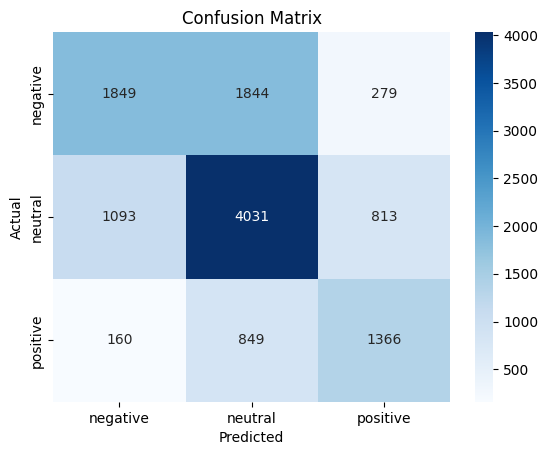

In [17]:
model.load_state_dict(torch.load("best_model.pt"))
model.eval()
preds, trues = [], []
with torch.no_grad():
    for x, l, y in test_dl:
        out = model(x.to(device), l.to(device)).argmax(1).cpu()
        preds += out.tolist(); trues += y.tolist()

print(classification_report(trues, preds, target_names=label_names, digits=3))

cm = confusion_matrix(trues, preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_names, yticklabels=label_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

In [18]:
test_df["pred"] = preds
wrong = test_df[test_df["label"] != test_df["pred"]].copy()
wrong["actual"] = wrong["label"].map(dict(enumerate(label_names)))
wrong["predicted"] = wrong["pred"].map(dict(enumerate(label_names)))

print("Misclassified:", len(wrong), "of", len(test_df))
print(wrong.groupby(["actual", "predicted"]).size().sort_values(ascending=False))
print()
for _, r in wrong.sample(15, random_state=1).iterrows():
    print(f"[{r['actual']} -> {r['predicted']}] {r['text'][:120]}")

# length ka effect
test_df["len"] = test_df["clean"].str.split().str.len()
print("\nAvg length (correct):", test_df[test_df.label == test_df.pred]["len"].mean())
print("Avg length (wrong):  ", test_df[test_df.label != test_df.pred]["len"].mean())

Misclassified: 5038 of 12284
actual    predicted
negative  neutral      1844
neutral   negative     1093
positive  neutral       849
neutral   positive      813
negative  positive      279
positive  negative      160
dtype: int64

[neutral -> positive] I'm officially giving up the #Hatchimals hunt now I mean it this time 😂
[neutral -> negative] names in each state. Many people who didn't like ACA, liked Medicaid which had a different name in their state. Tell Tru
[positive -> neutral] We need to start talking more about how Grayson Allen can play point guard in the NBA. Such a terrific and willing passe
[negative -> neutral] @user @user As Venezuelans you should be ashamed of yourselves! As if Chavez y Maduro's damage didn't have Bolivar turni
[positive -> negative] I must be having deja vú cuz I coulda swore thanksgiving was yesterday? #thanksgivingleftovers
[negative -> neutral] @user @user i used that as a for animal testing, broke my heart though as i completely disagree !! :( xx
[

In [19]:
def predict(text):
    ids, l = encode(clean(text))
    x = torch.tensor([ids]).to(device); ln = torch.tensor([l])
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(x, ln), dim=1)[0].cpu()
    return label_names[p.argmax().item()], round(p.max().item(), 3)

print(predict("I love this phone, battery is amazing"))
print(predict("worst service ever, never coming back"))

('positive', 1.0)
('negative', 0.993)


In [20]:
import pickle
pickle.dump(vocab, open("vocab.pkl", "wb"))
from google.colab import files
files.download("best_model.pt"); files.download("vocab.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>